In [50]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [52]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numeric = ['number_of_courses_viewed', 'annual_income', 'interaction_count',
       'lead_score']

df[categorical] = df[categorical].fillna('NA')
df[numeric] = df[numeric].fillna(0)

In [53]:
from sklearn.model_selection import train_test_split

In [54]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

QUESTION 1 :  ROC AUC feature importance

In [55]:
from sklearn.metrics import roc_auc_score, roc_curve

In [56]:
df.dtypes[df.dtypes != 'object'].index

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [57]:
for c in numeric:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print('%16s, %.3f' % (c, auc))


number_of_courses_viewed, 0.723
   annual_income, 0.608
interaction_count, 0.765
      lead_score, 0.788


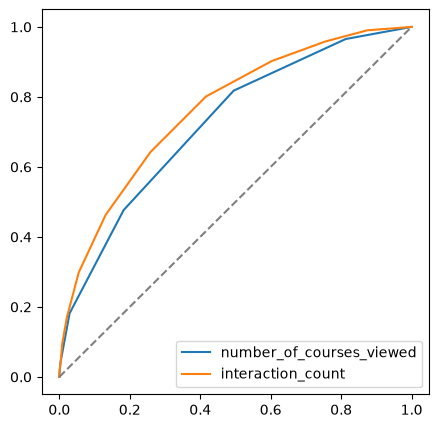

In [58]:
plt.figure(figsize=(5, 5))

fpr, tpr, _ = roc_curve(y_train, df_train.number_of_courses_viewed)
plt.plot(fpr, tpr, label='number_of_courses_viewed')

fpr, tpr, _ = roc_curve(y_train, df_train.interaction_count)
plt.plot(fpr, tpr, label='interaction_count')

plt.plot([0, 1], [0, 1], color='grey', linestyle='--')

plt.legend()
plt.show()

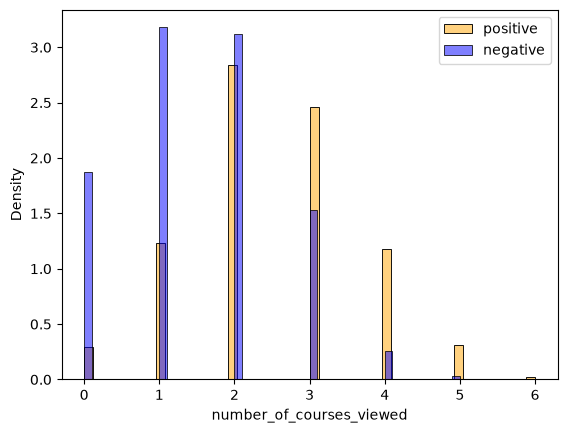

In [59]:
sns.histplot(df_train.number_of_courses_viewed[y_train == 1],
             stat='density', bins=50,
             color='orange', alpha=0.5,
             label='positive')
sns.histplot(df_train.number_of_courses_viewed[y_train == 0],
             stat='density', bins=50,
             color='blue', alpha=0.5,
             label='negative')

plt.legend()
plt.show()

QUESTION 2 : TRAINING MODEL

In [60]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression


In [61]:
train_dicts = df_train.to_dict(orient='records')
dv = DictVectorizer()
X_train = dv.fit_transform(train_dicts)

model = LogisticRegression(C=1.0, max_iter=1000)
model.fit(X_train, y_train)

val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

y_pred = model.predict_proba(X_val)[:, 1]

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [62]:
roc_auc_score(y_val, y_pred)

0.7885360505185405

Question 3: Precision and Recall

In [63]:
def confusion_matrix_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    return df_scores

In [64]:

df_scores = confusion_matrix_dataframe(y_val, y_pred)

In [65]:
df_scores[::10]

,threshold,tp,fp,fn,tn
0,0.0,586,414,0,0
10,0.1,583,397,3,17
20,0.2,573,348,13,66
30,0.3,556,283,30,131
40,0.4,526,223,60,191
50,0.5,474,170,112,244
60,0.6,416,110,170,304
70,0.7,330,65,256,349
80,0.8,230,36,356,378
90,0.9,95,7,491,407


In [66]:
df_scores['p'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['r'] = df_scores.tp / (df_scores.tp + df_scores.fn)

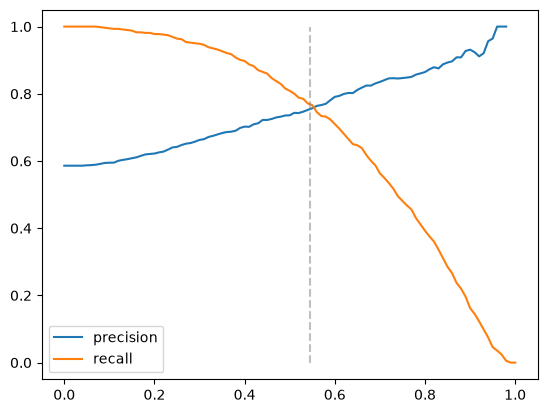

In [67]:
plt.plot(df_scores.threshold, df_scores.p, label='precision')
plt.plot(df_scores.threshold, df_scores.r, label='recall')

plt.vlines(0.545, 0, 1, color='grey', linestyle='--', alpha=0.5)

plt.legend()
plt.show()


Question 4: F1 score

In [68]:

df_scores['f1'] = 2 * df_scores.p * df_scores.r / (df_scores.p + df_scores.r)

In [69]:
df_scores.loc[df_scores.f1.argmax()]

threshold      0.400000
tp           526.000000
fp           223.000000
fn            60.000000
tn           191.000000
p              0.702270
r              0.897611
f1             0.788015
Name: 40, dtype: float64

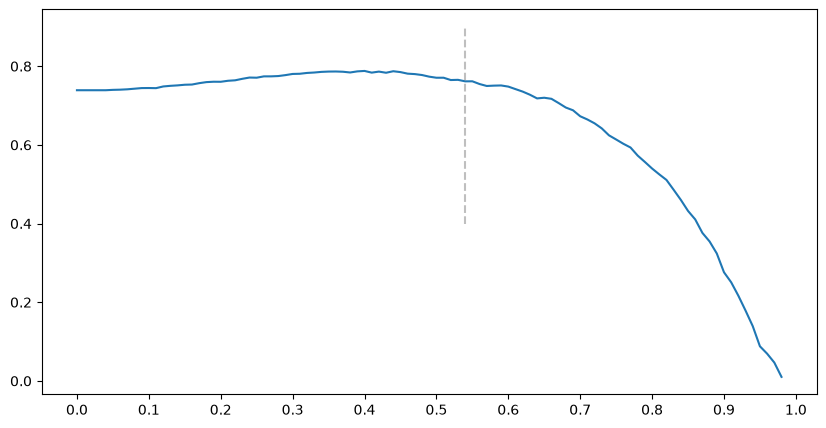

In [70]:
plt.figure(figsize=(10, 5))

plt.plot(df_scores.threshold, df_scores.f1)
plt.vlines(0.54, 0.4, 0.9, color='grey', linestyle='--', alpha=0.5)

plt.xticks(np.linspace(0, 1, 11))
plt.show()

Question 5: 5-Fold CV

In [71]:
from sklearn.model_selection import KFold

In [72]:
df.columns


Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [73]:
columns = list(df.columns)
columns.remove('converted')
columns

['lead_source',
 'industry',
 'employment_status',
 'location',
 'annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [90]:
def train(df_train, y_train, C=1.0):
    dicts = df_train.drop(columns=['converted']).to_dict(orient='records')

    dv = DictVectorizer()
    X_train = dv.fit_transform(dicts)

    X_train.indices = X_train.indices.astype(np.int32)
    X_train.indptr = X_train.indptr.astype(np.int32)

    model = LogisticRegression(
        solver='liblinear',
        C=C,
        max_iter=1000
    )
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df.drop(columns=['converted']).to_dict(orient='records')
    X = dv.transform(dicts)

    X.indices = X.indices.astype(np.int32)
    X.indptr = X.indptr.astype(np.int32)

    return model.predict_proba(X)[:, 1]

In [91]:
scores = []

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('%.3f +- %.3f' % (np.mean(scores), np.std(scores)))

0.732 +- 0.007


Question 6: Hyperparemeter Tuning

In [92]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%4s, %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06, 0.617 +- 0.019
C=0.001, 0.749 +- 0.010
C=   1, 0.732 +- 0.007


In [ ]:
import sklearn
import scipy
import numpy as np

print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("NumPy:", np.__version__)

Scikit-learn: 1.9.1
SciPy: 1.18.1
NumPy: 2.5.3
